# Redes Neuronales Recurrentes
# Ejemplos Varios<a class="tocSkip">
## Reconocimiento de Patrones <a class="tocSkip">
### Ingenieria Electrónica <a class="tocSkip">
### Universidad Popular del Cesar <a class="tocSkip">
### Prof.: Jose Ramón Iglesias Gamarra - [https://github.com/joseramoniglesias/](https://github.com/joseramoniglesias/) <a class="tocSkip">
  **joseiglesias@unicesar.edu.co**

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Input

In [2]:
# load the imdb dataset
max_features=10000
(X_train,y_train),(X_test,y_test) = imdb.load_data(num_words=max_features)

print(f'Training data shape: {X_train.shape}, Training labels shape: {y_train.shape}')
print(f'Testing data shape: {X_test.shape}, Testing labels shape: {y_test.shape}')

Training data shape: (25000,), Training labels shape: (25000,)
Testing data shape: (25000,), Testing labels shape: (25000,)


In [3]:
# inspect a sample review and its label
sample_review = X_train[0]
sample_label = y_train[0]
print(f'Sample review: {sample_review}')
print(f'Sample label: {sample_label}')

Sample review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]
Sample label: 1


In [4]:
max_len = 500
X_train = sequence.pad_sequences(X_train,maxlen=max_len)
X_test = sequence.pad_sequences(X_test,maxlen=max_len)

In [5]:
X_train[0]

array([   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,   

In [7]:
# RNN model
model = Sequential([
    Embedding(input_dim=max_features,output_dim=128),
    SimpleRNN(128, activation='tanh'),
    Dense(1, activation='sigmoid')
])

In [8]:
model.predict(X_train)
model.summary()

782/782 ━━━━━━━━━━━━━━━━━━━━ 26s 33ms/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (32, 500, 128)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (32, 128)              │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 1)                │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,025 (5.01 MB)

 Trainable params: 1,313,025 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [10]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)

In [11]:
history = model.fit(X_train,y_train,epochs=10,batch_size=32,validation_split=0.2,callbacks=[early_stopping])

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 80s 125ms/step - accuracy: 0.5428 - loss: 0.6874 - val_accuracy: 0.6184 - val_loss: 0.6385
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 130ms/step - accuracy: 0.7010 - loss: 0.5797 - val_accuracy: 0.6362 - val_loss: 0.6325
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 74s 119ms/step - accuracy: 0.7223 - loss: 0.5494 - val_accuracy: 0.6756 - val_loss: 0.6167
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 75s 120ms/step - accuracy: 0.8012 - loss: 0.4403 - val_accuracy: 0.7216 - val_loss: 0.5715
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 124ms/step - accuracy: 0.8285 - loss: 0.3972 - val_accuracy: 0.7188 - val_loss: 0.5837
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 74s 118ms/step - accuracy: 0.8383 - loss: 0.3831 - val_accuracy: 0.7116 - val_loss: 0.6142
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 70s 112ms/step - accuracy: 0.8561 - loss: 0.3528 - val_accuracy: 0.7220 - val_loss: 0.6287
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 71s 114ms/step - accuracy: 0.8759 - loss: 0

In [12]:
model.get_weights()

[array([[-0.08604082,  0.19501223,  0.11066563, ..., -0.11548319,
          0.01069812,  0.03071599],
        [ 0.00666971,  0.01346179, -0.03578404, ...,  0.13444869,
         -0.04127845,  0.06205021],
        [-0.00446187, -0.08472375, -0.02295824, ...,  0.05204248,
          0.03258677,  0.02693871],
        ...,
        [-0.03212647,  0.02706403,  0.00384188, ..., -0.0280993 ,
          0.02892698,  0.04962029],
        [-0.10708416,  0.08367135, -0.00739845, ...,  0.02227661,
         -0.11976684,  0.0106608 ],
        [ 0.04302065,  0.09180798, -0.04803216, ...,  0.03366504,
         -0.03470699,  0.07650305]], dtype=float32),
 array([[ 0.14769734, -0.15506402,  0.09567232, ...,  0.12257586,
         -0.13523507, -0.14601305],
        [-0.01526627,  0.16402285, -0.16407242, ..., -0.00325987,
          0.06398129,  0.01830905],
        [ 0.04956469,  0.08757813, -0.1588745 , ..., -0.12028247,
         -0.02595848,  0.0424154 ],
        ...,
        [ 0.05107589,  0.10911003,  0.0

In [13]:
# Get the word index mappings (needed to decode/encode reviews)
word_index = imdb.get_word_index()
reverse_word_index = {value: key for key, value in word_index.items()}

# Function to decode reviews
def decode_review(encoded_review):
  return ' '.join([reverse_word_index.get(i-3,'?') for i in encoded_review])

def preprocess_text(text):
  words = text.lower().split()
  encoded_review = [word_index.get(word,2)+3 for word in words]
  padded_review = sequence.pad_sequences([encoded_review],maxlen=500)
  return padded_review


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 5s 3us/step  


In [14]:
def predict_sentiment(review):
  preprocessed_input = preprocess_text(review)

  prediction = model.predict(preprocessed_input)
  sentiment = 'Positive' if prediction[0][0] > 0.5 else 'Negative'

  return sentiment, prediction[0][0]

In [15]:
example_review = "This movie was great and I loved it!"
sentiment,score = predict_sentiment(example_review)

print(f'Review: {example_review}')
print(f'Sentiment: {sentiment}')
print(f'Prediction Score: {score}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step
Review: This movie was great and I loved it!
Sentiment: Positive
Prediction Score: 0.9454740285873413


In [16]:
y_pred = model.predict(X_test)
y_pred = np.where(y_pred > 0.5, 1, 0)

782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step


In [17]:
y_pred_prob = model.predict(X_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step


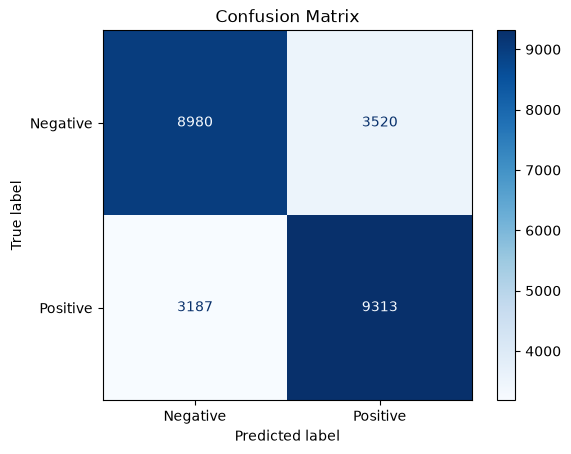

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Negative','Positive']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

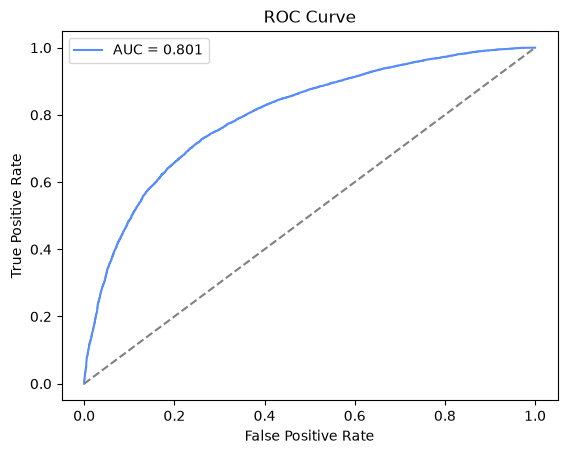

In [19]:
from sklearn.metrics import roc_auc_score, roc_curve

# y_pred_prob = raw sigmoid outputs (shape (25000, 1))
auc = roc_auc_score(y_test, y_pred_prob)
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)

plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(); plt.title('ROC Curve')
plt.show()

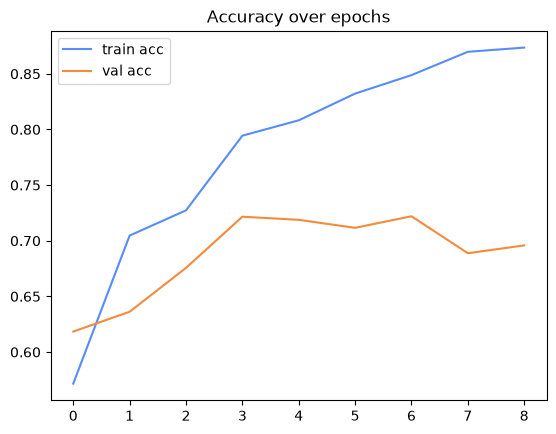

In [20]:
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend(); plt.title('Accuracy over epochs')
plt.show()